<a href="https://colab.research.google.com/github/keyvanmahmoudi/Deep_Learning_Course/blob/main/solutions/Session01_perceptron_and_mlp_solutions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

# پاسخ تمرین‌های جلسهٔ ۱: از یادگیری ماشین تا یادگیری عمیق: Perceptron و MLP

این نوت‌بوک پاسخ پیشنهادی تمرین‌های انتهای [نوت‌بوک جلسه](../sessions/Session01_perceptron_and_mlp.ipynb) است. قبل از دیدن پاسخ‌ها، خودتان تمرین‌ها را حل کنید؛ معمولاً بیش از یک راه‌حل درست وجود دارد.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### آماده‌سازی

</div>

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)


def step(z):
    return (z >= 0).astype(int)


class Perceptron:
    def __init__(self, n_features, lr=0.1):
        self.w, self.b, self.lr = np.zeros(n_features), 0.0, lr

    def predict(self, X):
        return step(X @ self.w + self.b)

    def fit(self, X, y, epochs=20):
        history = []
        for _ in range(epochs):
            errors = 0
            for i in np.random.permutation(len(X)):
                update = self.lr * (y[i] - self.predict(X[i:i + 1])[0])
                self.w += update * X[i]
                self.b += update
                errors += int(update != 0)
            history.append(errors)
            if errors == 0:
                break
        return history

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۱

وزن‌ها و بایاس یک پرسپترون را طوری تعیین کنید که تابع NAND را پیاده کند. چرا NAND به‌تنهایی برای ساخت هر مدار منطقی کافی است؟

</div>

In [2]:
X_gate = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
w_nand, b_nand = np.array([-1.0, -1.0]), 1.5
print('inputs :', X_gate.tolist())
print('NAND   :', step(X_gate @ w_nand + b_nand))

# NOT, AND and OR built only from NAND gates
nand = lambda a, b: step(np.array([a, b]) @ w_nand + b_nand)
NOT = lambda a: nand(a, a)
AND = lambda a, b: NOT(nand(a, b))
OR = lambda a, b: nand(NOT(a), NOT(b))
print('AND from NAND:', [int(AND(a, b)) for a, b in X_gate])
print('OR  from NAND:', [int(OR(a, b)) for a, b in X_gate])

inputs : [[0, 0], [0, 1], [1, 0], [1, 1]]
NAND   : [1 1 1 0]
AND from NAND: [0, 0, 0, 1]
OR  from NAND: [0, 1, 1, 1]


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

NAND فقط وقتی صفر است که هر دو ورودی یک باشند؛ پس با وزن‌های منفی و بایاس مثبت (مثلاً $w = (-1, -1)$ و $b = 1.5$) پیاده می‌شود. NAND یک **دروازهٔ کامل (Functionally Complete)** است: همان‌طور که در کد دیدید، NOT، AND و OR (و در نتیجه هر تابع منطقی دیگر) را می‌توان فقط با ترکیب NAND ساخت. این یعنی شبکه‌ای از پرسپترون‌ها، اگر چندلایه باشد، می‌تواند هر مدار منطقی را بسازد؛ همان ایدهٔ حل XOR در جلسه.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۲

کلاس `Perceptron` را روی داده‌ای اجرا کنید که دو خوشه آن کمی هم‌پوشانی دارند (مثلاً مراکز را به هم نزدیک کنید). چه اتفاقی برای نمودار تعداد خطا در هر Epoch می‌افتد؟

</div>

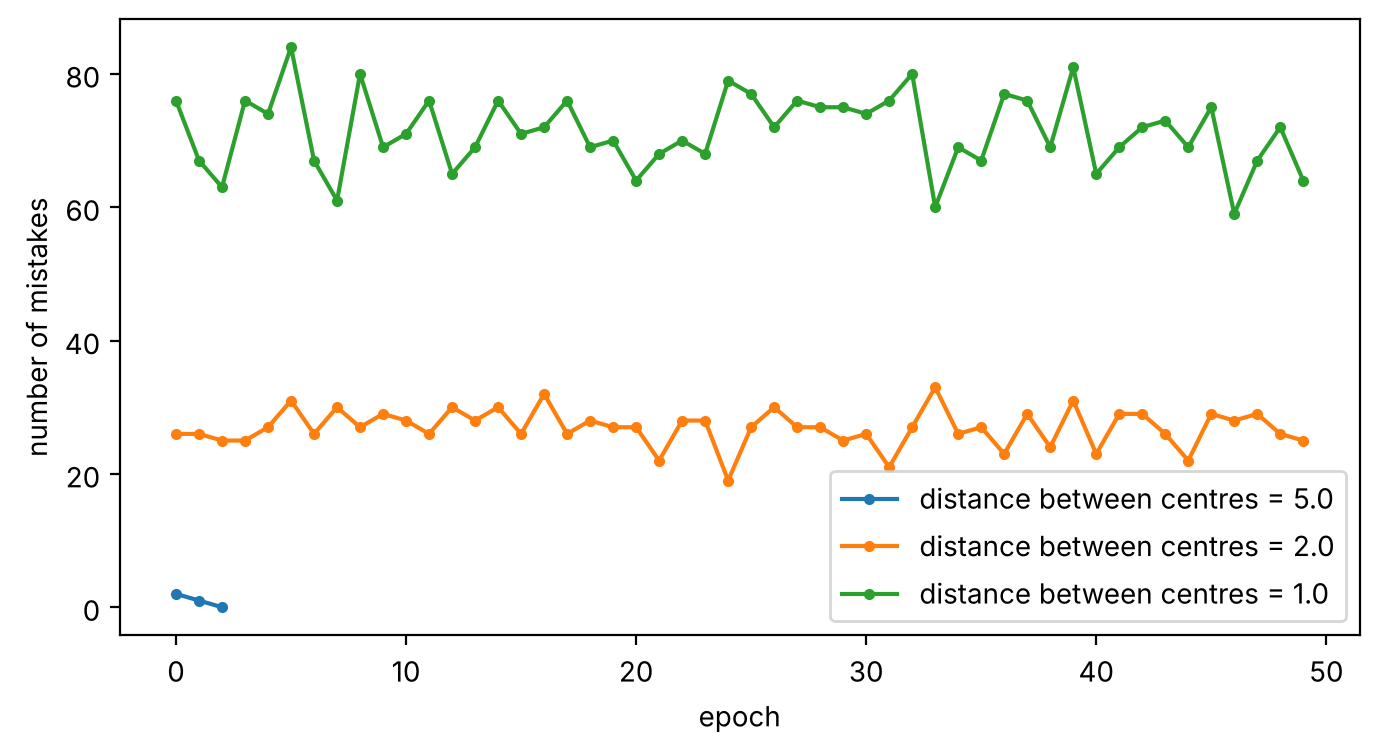

In [3]:
def make_blobs_2(distance, n=100, seed=0):
    rng = np.random.default_rng(seed)
    X0 = rng.normal(size=(n, 2)) * 0.8 + np.array([-distance / 2, 0])
    X1 = rng.normal(size=(n, 2)) * 0.8 + np.array([distance / 2, 0])
    return np.vstack([X0, X1]), np.array([0] * n + [1] * n)


plt.figure(figsize=(8, 4))
for distance in (5.0, 2.0, 1.0):
    X, y = make_blobs_2(distance)
    history = Perceptron(2).fit(X, y, epochs=50)
    plt.plot(history, 'o-', ms=3, label=f'distance between centres = {distance}')
plt.xlabel('epoch'); plt.ylabel('number of mistakes'); plt.legend(); plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

وقتی خوشه‌ها از هم دورند، تعداد خطا سریع صفر می‌شود و الگوریتم متوقف می‌شود. وقتی هم‌پوشانی دارند، داده **خطی‌جداپذیر نیست** و قضیهٔ همگرایی دیگر صادق نیست: تعداد خطا هیچ‌وقت صفر نمی‌شود و نمودار تا آخر نوسان می‌کند، چون هر به‌روزرسانی برای اصلاح یک نمونه، نمونهٔ دیگری را خراب می‌کند. به همین دلیل در عمل به‌جای قانون پرسپترون، یک **تابع هزینهٔ پیوسته** را کمینه می‌کنیم (جلسهٔ ۲) که حتی برای دادهٔ هم‌پوشان هم بهترین مرز ممکن را پیدا می‌کند.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۳

تعداد پارامترهای یک MLP با ساختار `[784, 256, 128, 10]` (طبقه‌بندی تصاویر ۲۸×۲۸) را حساب کنید و با `MLP(...).n_parameters()` بررسی کنید.

</div>

In [4]:
class MLP:
    def __init__(self, layer_sizes, seed=0):
        rng = np.random.default_rng(seed)
        self.params = [(rng.normal(0, np.sqrt(2 / n_in), (n_in, n_out)), np.zeros(n_out))
                       for n_in, n_out in zip(layer_sizes[:-1], layer_sizes[1:])]

    def n_parameters(self):
        return sum(W.size + b.size for W, b in self.params)


sizes = [784, 256, 128, 10]
by_hand = sum(n_in * n_out + n_out for n_in, n_out in zip(sizes[:-1], sizes[1:]))
print('by hand :', f'{784 * 256 + 256:,} + {256 * 128 + 128:,} + {128 * 10 + 10:,} = {by_hand:,}')
print('by code :', f'{MLP(sizes).n_parameters():,}')

by hand : 200,960 + 32,896 + 1,290 = 235,146
by code : 235,146


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

لایهٔ اول به‌تنهایی بیش از ۸۵٪ پارامترها را دارد، چون ورودی ۷۸۴ بعدی است. این همان مشکلی است که در جلسهٔ ۷ می‌بینیم: برای تصاویر بزرگ‌تر، لایه‌های Fully Connected بسیار پرهزینه می‌شوند و شبکه‌های کانولوشنی راه‌حل آن هستند.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۴

در آزمایش تقریب جهانی، تابع هدف را به $|x|$ و سپس به یک تابع پله‌ای تغییر دهید. کدام سخت‌تر تقریب زده می‌شود و چرا؟

</div>

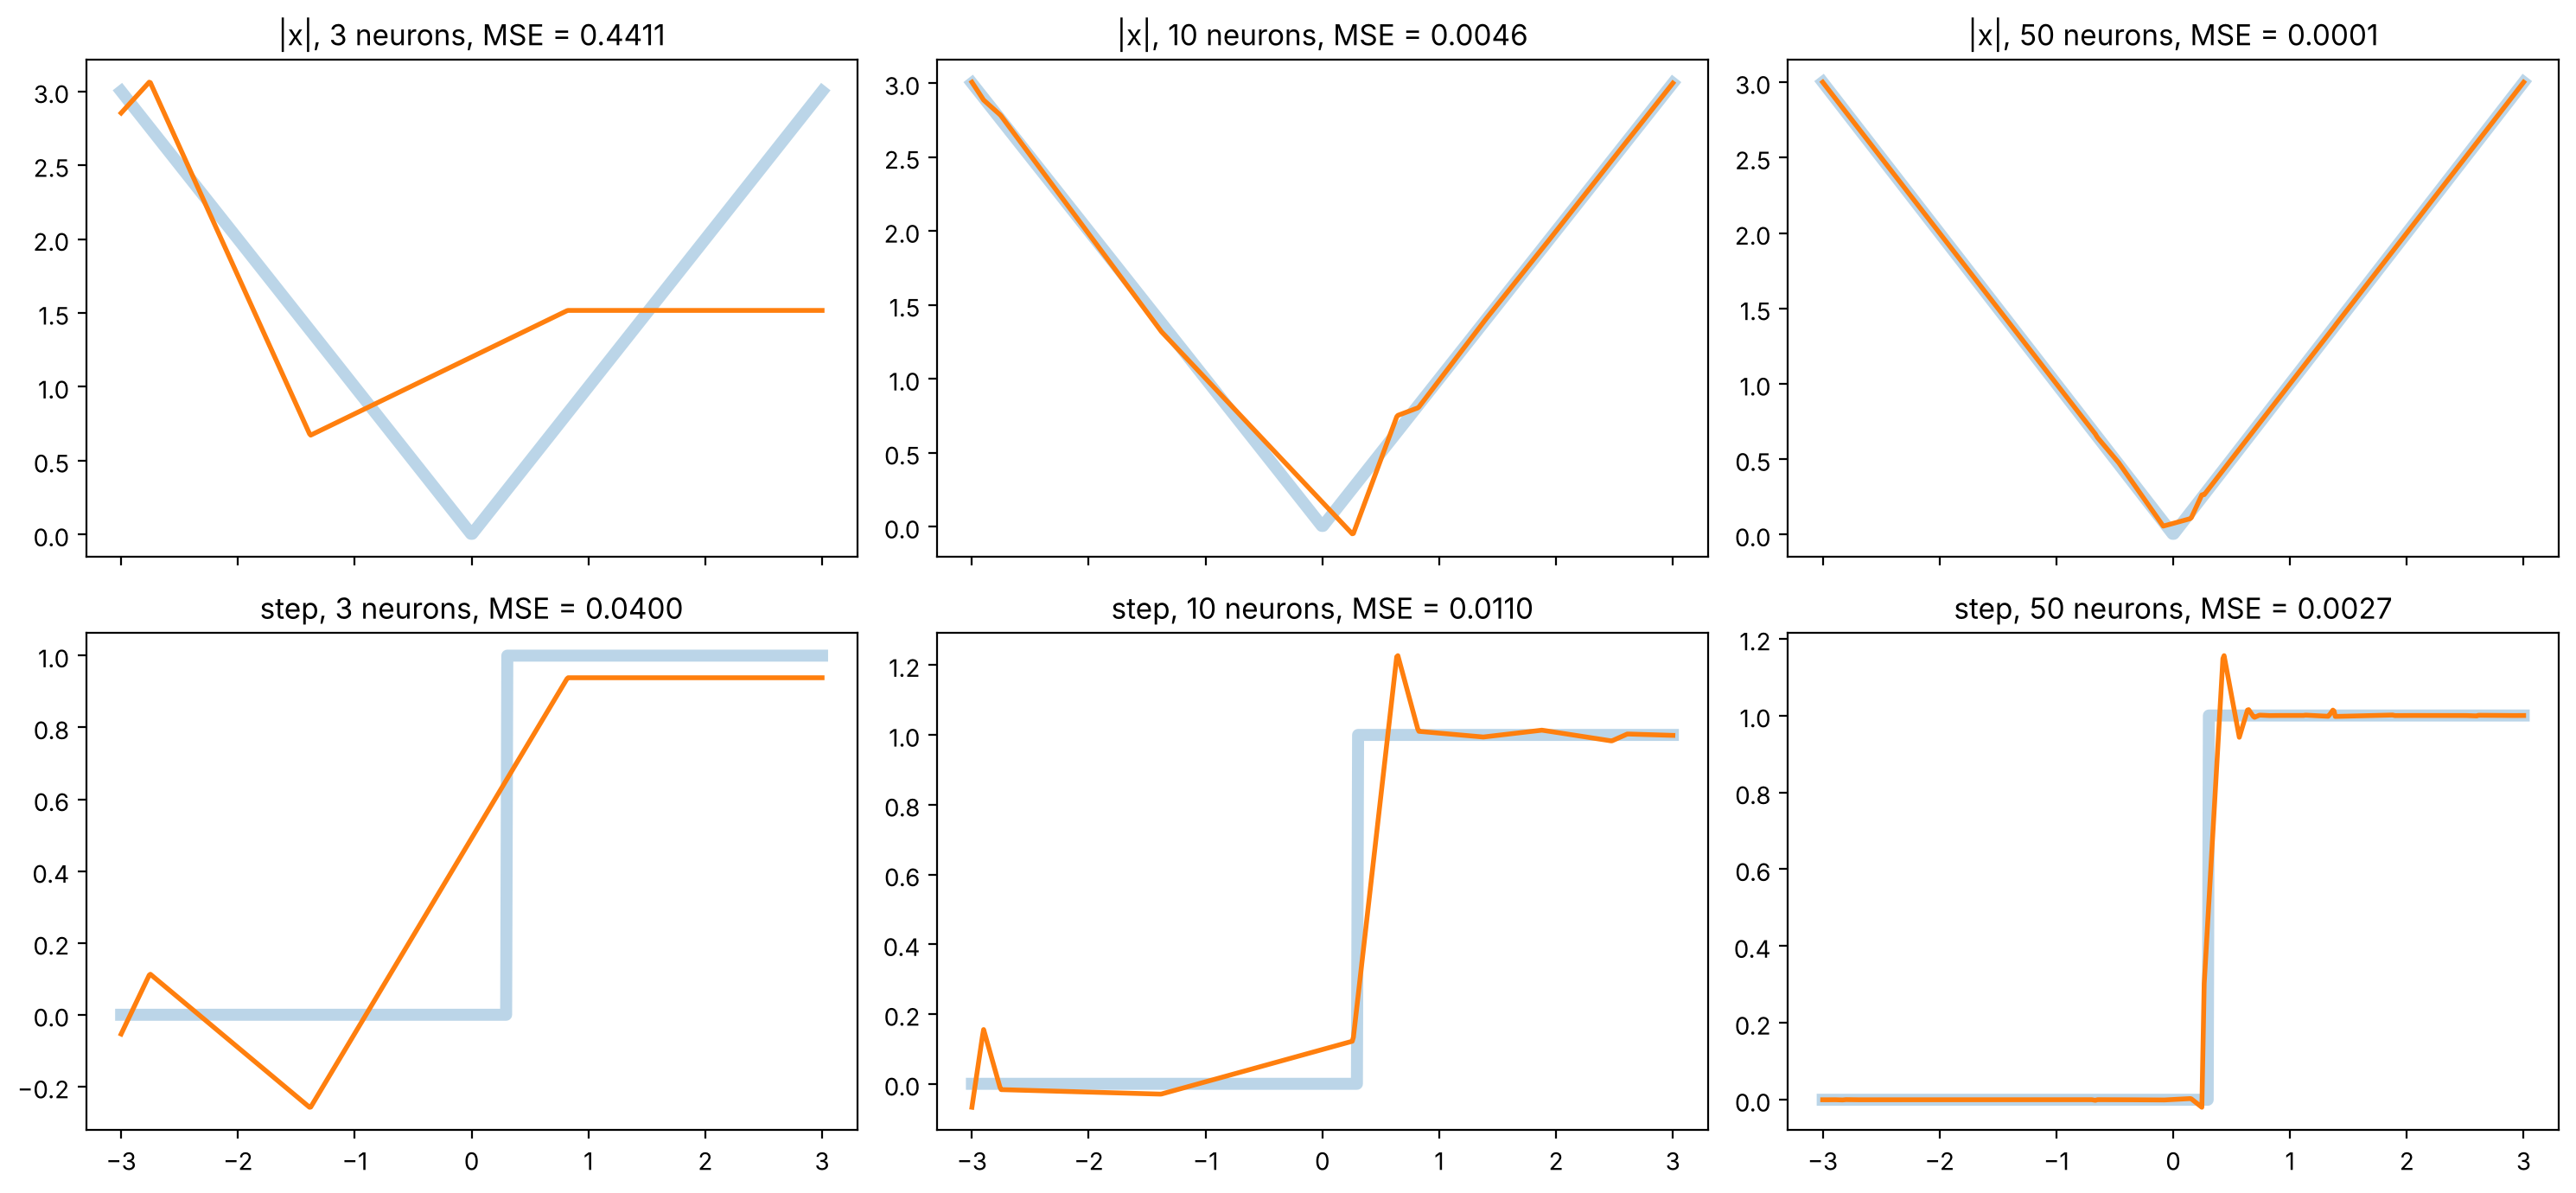

In [5]:
def fit_relu_features(x, target, n_hidden, seed=0):
    rng = np.random.default_rng(seed)
    breakpoints, signs = rng.uniform(-3, 3, n_hidden), rng.choice([-1, 1], n_hidden)
    H = np.c_[np.maximum(0, signs * (x[:, None] - breakpoints)), np.ones_like(x)]
    w, *_ = np.linalg.lstsq(H, target, rcond=None)
    return H @ w


x = np.linspace(-3, 3, 600)
targets = {'|x|': np.abs(x), 'step': (x > 0.3).astype(float)}
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex=True)
for row, (name, target) in zip(axes, targets.items()):
    for ax, n in zip(row, [3, 10, 50]):
        approx = fit_relu_features(x, target, n)
        mse = np.mean((approx - target) ** 2)
        ax.plot(x, target, lw=5, alpha=0.3); ax.plot(x, approx, lw=2)
        ax.set_title(f'{name}, {n} neurons, MSE = {mse:.4f}')
plt.tight_layout(); plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

تابع $|x|$ خودش از دو تکهٔ خطی ساخته شده و با ReLU تقریباً به‌طور کامل قابل بیان است: کافی است یکی از نورون‌ها شکستگی‌اش نزدیک صفر باشد. تابع پله‌ای **ناپیوسته** است و ترکیبی از توابع خطی پیوسته هرگز نمی‌تواند یک پرش واقعی بسازد؛ فقط می‌تواند با شیب تند به آن نزدیک شود. پس خطا نزدیک نقطهٔ پرش باقی می‌ماند و برای کم کردن آن نورون‌های بیشتری لازم است. قضیهٔ تقریب جهانی هم فقط برای توابع **پیوسته** تضمین می‌دهد.

</div>